# Rolling-Horizon DITL Example

## Introduction

COASTSim can decide what a spacecraft observes in three ways:

* `QueueDITL` picks the next target each time the spacecraft is free, like an
  autonomous on-board scheduler.
* `DITL` executes a plan built in advance, start to finish.
* `RollingHorizonDITL` models a mission planned on the ground. It builds a plan
  for the next few hours, follows it, and rebuilds it on a regular schedule from
  wherever the spacecraft actually is. Targets of Opportunity (ToOs) join the next
  plan, or force an immediate replan if they can't wait.

This notebook runs a one-day `RollingHorizonDITL` simulation with 100 targets and
one ToO, looks at what each replan did, and compares the result with `QueueDITL`
on the same targets.

## Step 1: Import Libraries

In [1]:
%matplotlib ipympl
from datetime import datetime, timedelta, timezone

import numpy as np
from rust_ephem import TLEEphemeris

from conops import RollingHorizonDITL
from conops.config import MissionConfig, Telescope, TelescopeConfig, TelescopeType
from conops.targets import Pointing
from conops.visualization import plot_ditl_timeline, plot_sky_pointing

## Step 2: Spacecraft Configuration and Ephemeris

We use the default `MissionConfig` with a small telescope, as in the Quick DITL
example, and load a one-day ephemeris from a TLE.

The planner works out visibility, slews and ground passes from the ephemeris on
the configuration's constraint, so we attach it there too.

In [2]:
config = MissionConfig()
config.payload.instruments.append(
    Telescope(
        name="Telescope f/7 0.5m",
        optics=TelescopeConfig(
            aperture_m=0.5,
            focal_length_m=3.5,
            telescope_type=TelescopeType.RITCHEY_CHRETIEN,
            tube_length_m=1.0,
        ),
    )
)
config.constraint.ignore_roll = True
config.spacecraft_bus.attitude_control.slew_before_visible = True

begin = datetime(2025, 12, 1, tzinfo=timezone.utc)
end = begin + timedelta(days=1)
ephemeris = TLEEphemeris(begin=begin, end=end, step_size=60, tle="example.tle")
config.constraint.ephem = ephemeris

EOP2 text loaded from cache: /Users/jamiekennea/.cache/rust_ephem/latest_eop2.short (age: 13487s)
UT1 provider initialized (EOP2 short, cached)


## Step 3: Create the Targets

`RollingHorizonDITL` plans from a list of `Pointing` targets. Each one has:

* `merit`: its priority. Higher-merit targets are planned first.
* `exptime`: the total exposure it needs, in seconds.
* `ss_min` / `ss_max`: the shortest and longest single observation (snapshot).
  Here each target needs 2000 s, observed in snapshots of 300 to 1000 s, so it
  takes at least two visits.

We create 100 targets at random positions. That asks for about 55 hours of
exposure in a 24-hour day, so not everything will fit, and the planner has to
choose.

In [3]:
rng = np.random.default_rng(5)

targets = []
for i in range(100):
    target = Pointing(
        config=config,
        ra=rng.uniform(0, 360),
        dec=rng.uniform(-90, 90),
        obsid=10000 + i,
        name=f"Target {i}",
        merit=rng.uniform(10, 100),
        ss_min=300,
        ss_max=1000,
    )
    target.exptime = 2000
    targets.append(target)

## Step 4: Create the Rolling-Horizon DITL

The main settings:

* `horizon`: how far ahead each plan looks.
* `replan_interval`: how often the plan is rebuilt.
* `commit_lead_time`: how long a new plan takes to reach the spacecraft.
  Anything already commanded, or due to start within this time, is kept when the
  plan is rebuilt; everything after it is planned again.
* `rapid_replans`: whether an urgent ToO triggers an immediate replan.
* `allow_interrupts`: whether that replan may cut short the observation in
  progress.

Here we plan 12 hours ahead, replan every 6 hours, and allow 15 minutes for a
plan to be uplinked.

In [4]:
ditl = RollingHorizonDITL(
    config,
    targets,
    ephem=ephemeris,
    begin=begin,
    end=end,
    horizon=timedelta(hours=12),
    replan_interval=timedelta(hours=6),
    commit_lead_time=timedelta(minutes=15),
    rapid_replans=True,
    allow_interrupts=True,
)

## Step 5: Submit a Target of Opportunity

A gamma-ray burst is reported 8 hours into the day, and must be observed within
45 minutes. The next scheduled replan isn't until 12:00, which is too late, so
this ToO triggers a rapid replan as soon as it arrives. Its merit (1000) is far
above any target in the plan, so the observation running at the commit cutoff is
cut short for it.

In [5]:
ditl.submit_too(
    obsid=900001,
    ra=150.0,
    dec=30.0,
    merit=1000,
    exptime=600,
    name="GRB 251201A",
    submit_time=begin + timedelta(hours=8),
    deadline=begin + timedelta(hours=8, minutes=45),
)

TOORequest(obsid=900001, ra=150.0, dec=30.0, merit=1000.0, exptime=600, name='GRB 251201A', submit_time=1764576000.0, deadline=1764578700.0, executed=False)

## Step 6: Run the Simulation

`calc()` builds the first plan, then runs the day, replanning as it goes. Most of
the run time is spent planning; the time for each replan is recorded below.

In [6]:
%%time
ditl.calc()

CPU times: user 3.35 s, sys: 20.2 ms, total: 3.37 s
Wall time: 3.37 s


True

## Step 7: What Each Replan Did

`ditl.replans` has one record per replan:

* `reason`: `initial`, `scheduled`, or `rapid` (triggered by a ToO).
* `cutoff`: activities starting before this time were already committed and kept.
* `kept` / `dropped` / `added`: committed entries still running, planned entries
  that were thrown away, and entries in the new plan.
* `unplaced`: targets the new plan couldn't fit.
* `trigger_obsid` / `interrupted_obsid`: for a rapid replan, the ToO and the
  observation cut short for it.

In [7]:
def hhmm(utime: float) -> str:
    return datetime.fromtimestamp(utime, tz=timezone.utc).strftime("%H:%M")


print(
    f"{'time':>5}  {'reason':<9} {'cutoff':>6} {'kept':>4} {'dropped':>7} "
    f"{'added':>5} {'unplaced':>8} {'plan time':>9}  ToO / interrupted"
)
for r in ditl.replans:
    too = f"{r.trigger_obsid} / {r.interrupted_obsid}" if r.trigger_obsid else ""
    print(
        f"{hhmm(r.utime):>5}  {r.reason.value:<9} {hhmm(r.cutoff):>6} {r.kept:>4} "
        f"{r.dropped:>7} {r.added:>5} {r.unplaced:>8} {r.planning_seconds:>8.1f}s  {too}"
    )

 time  reason    cutoff kept dropped added unplaced plan time  ToO / interrupted
00:00  initial    00:00    0       0    34       87      0.6s  
06:00  scheduled  06:15    1      17    34       79      0.6s  
08:00  rapid      08:15    1      28    34       78      0.9s  900001 / 10038
12:00  scheduled  12:15    2      22    34       73      0.5s  
18:00  scheduled  18:15    1      17    17       73      0.2s  


## Step 8: ToO Response and Plan Checks

`too_response_times()` gives the seconds from each ToO's submission to its first
science, or `None` if it was never observed.

`ditl.plan` is the plan that was actually followed: the committed part of every
plan. `validate_plan_matches_execution()` checks that the simulation executed it
exactly; an empty list means no mismatches.

In [8]:
for obsid, seconds in ditl.too_response_times().items():
    if seconds is None:
        print(f"ToO {obsid}: not observed")
    else:
        print(f"ToO {obsid}: first science {seconds / 60:.1f} min after submission")

print("Plan/execution mismatches:", ditl.validate_plan_matches_execution())

ToO 900001: first science 20.5 min after submission
Plan/execution mismatches: []


## Step 9: Progress on the Targets

Collected science is credited to the targets as the simulation runs, so their
remaining `exptime` and `collected_seconds` show what the day achieved.

In [9]:
science_hours = sum(hk.collection_seconds for hk in ditl.telemetry.housekeeping) / 3600
started = [t for t in targets if t.collected_seconds > 0]
finished = [t for t in targets if t.done]

print(f"Science collected:  {science_hours:.1f} h")
print(f"Targets observed:   {len(started)} of {len(targets)}")
print(f"Targets completed:  {len(finished)}")
print()
print("Highest-merit targets:")
for t in sorted(targets, key=lambda t: t.merit, reverse=True)[:10]:
    print(
        f"  {t.name:<10} merit {t.merit:5.1f}  "
        f"collected {t.collected_seconds:6.0f} s  remaining {t.exptime:6.0f} s"
    )

Science collected:  15.6 h
Targets observed:   29 of 100
Targets completed:  18

Highest-merit targets:
  Target 98  merit  99.9  collected   2000 s  remaining      0 s
  Target 57  merit  99.1  collected      0 s  remaining   2000 s
  Target 69  merit  98.3  collected   1956 s  remaining     44 s
  Target 17  merit  95.6  collected   2000 s  remaining      0 s
  Target 90  merit  95.2  collected   2000 s  remaining      0 s
  Target 47  merit  94.7  collected   1900 s  remaining    100 s
  Target 30  merit  93.1  collected   2000 s  remaining      0 s
  Target 64  merit  93.0  collected   1960 s  remaining     40 s
  Target 4   merit  90.8  collected   2000 s  remaining      0 s
  Target 84  merit  90.3  collected   2000 s  remaining      0 s


## Step 10: Visualize the Results

The same plots as for any other DITL. The sky map shows the pointing over the
day; the timeline shows observations, slews, ground passes and the ToO.

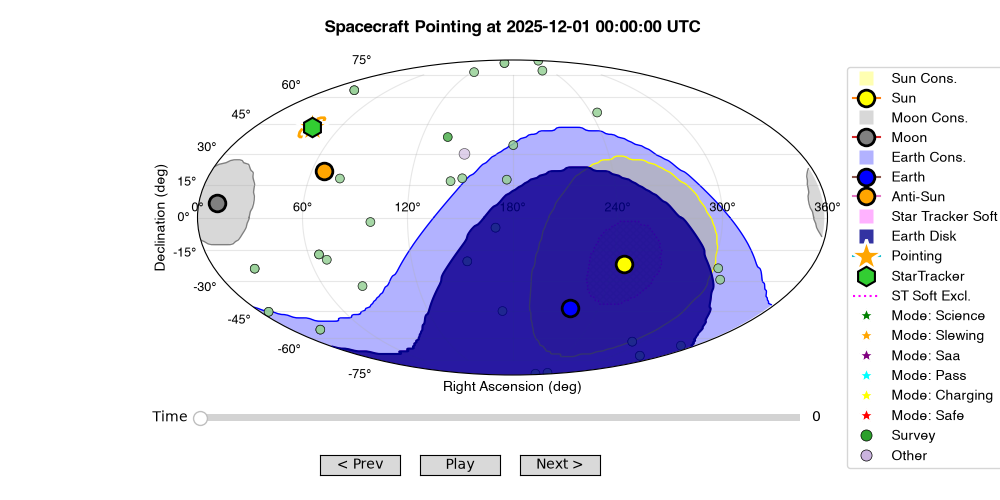

In [10]:
import matplotlib.pyplot as plt

_ = plot_sky_pointing(ditl, figsize=(10, 5))
plt.show()

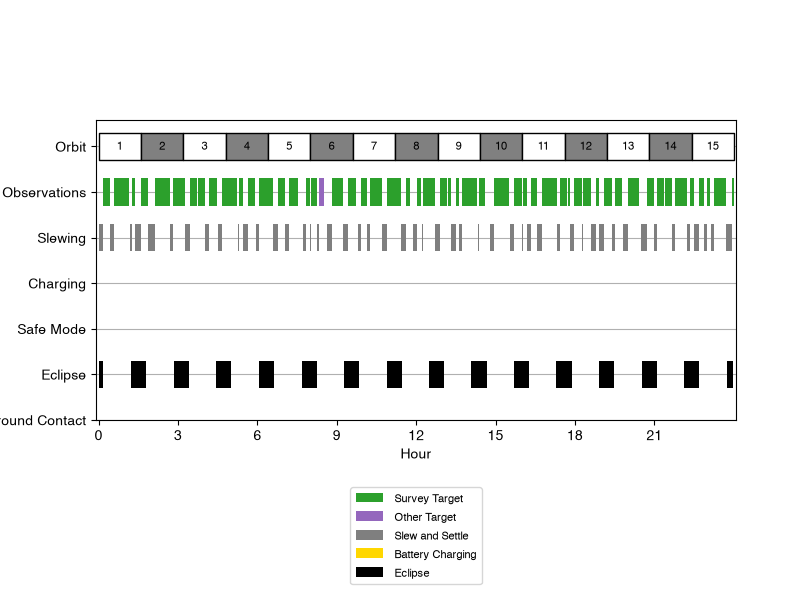

In [11]:
_ = plot_ditl_timeline(ditl, figsize=(8, 6))

(<Figure size 1000x800 with 1 Axes>,
 <Axes: title={'center': 'Percentage of Time Spent in Each ACS Mode'}>)

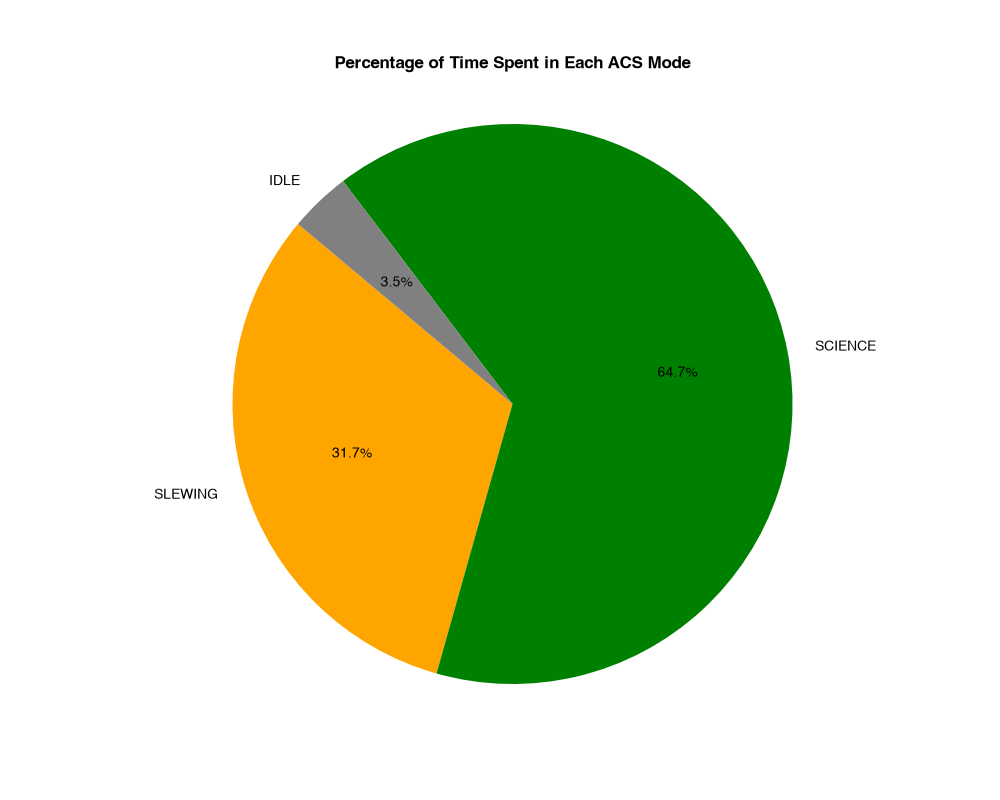

In [12]:
from conops.visualization import plot_acs_mode_distribution

plot_acs_mode_distribution(ditl)

## Step 11: Compare with Queue Dispatch

For comparison, we run `QueueDITL` on the same targets and ToO. It picks the next
target on board each time the spacecraft is free, so it can react to the ToO as
soon as it arrives. The rolling-horizon run has to wait for the commit lead time
before a new plan takes effect, but planning several hours at a time lets it fit
observations together more tightly. Here that gives it a little more science,
and a later ToO response.

In [13]:
from conops.ditl.queue_ditl import QueueDITL

queue_ditl = QueueDITL(config=config, ephem=ephemeris, begin=begin, end=end)
rng = np.random.default_rng(5)
for i in range(100):
    queue_ditl.queue.add(
        ra=rng.uniform(0, 360),
        dec=rng.uniform(-90, 90),
        obsid=10000 + i,
        name=f"Target {i}",
        merit=rng.uniform(10, 100),
        exptime=2000,
        ss_min=300,
        ss_max=1000,
    )
queue_ditl.submit_too(
    obsid=900001,
    ra=150.0,
    dec=30.0,
    merit=1000,
    exptime=600,
    name="GRB 251201A",
    submit_time=begin + timedelta(hours=8),
    deadline=begin + timedelta(hours=8, minutes=45),
)
queue_ditl.calc()

True

In [14]:
def summary(run) -> tuple[float, str]:
    hours = sum(hk.collection_seconds for hk in run.telemetry.housekeeping) / 3600
    too = [e for e in run.plan if e.obsid == 900001 and e.collection_begin is not None]
    first = hhmm(min(e.collection_begin for e in too)) if too else "never"
    return hours, first


for label, run in (("Rolling horizon", ditl), ("Queue dispatch", queue_ditl)):
    hours, first = summary(run)
    print(f"{label:<16} science {hours:5.1f} h   ToO first observed at {first}")

Rolling horizon  science  15.6 h   ToO first observed at 08:20
Queue dispatch   science  11.7 h   ToO first observed at 08:06


## Step 12: Save the Plan to Disk

The plan that was followed can be saved like any other plan, and executed again
later with `DITL`.

In [15]:
ditl.plan.save(".")

PosixPath('/Users/jamiekennea/ConOps/coast-sim/examples/plan_20251201T000000Z_20251202T000000Z_v3.json')